# Case Study 16 — How Much Can a Merchant Borrow? Cash-Flow Forecasting from QR Data, Burden-Based Limits, and Fuzzy KYC Name Matching

**Priority:** ★★ Good to have · **Reference:** Case Study 16 — *BharatPe: merchant lending from QR transaction data and automated KYC* (`indian_fintech_data_science_case_studies.md`)
**Audience:** Head of Merchant Lending, Credit Policy, KYC Operations, Finance
**Data:** ⚠️ **SYNTHETIC** (D-16-01). Merchant settlement, loan and KYC data are confidential; this is a calibrated simulation.
**Reproducibility:** seed = 42 · `python -m nbconvert --to notebook --execute --inplace cs16_merchant_qr_lending.ipynb`

## 0. Executive Summary for Business

*(Synthetic data built on BharatPe's documented design; BharatPe disclosed only the turnaround gain. Written after the analysis.)*

- **The question:** how much should each merchant be offered automatically, based on their QR payments, and when can the KYC-vs-bank-account name check be passed without a human?
- **Size loans by repayment burden, not by turnover.** Default rises steadily with the daily instalment as a share of daily QR inflow: from **3.6% when it is under 6% to 31% when it is over 30%** (trend p ≈ 1e-100).
  - The legacy rule ("lend one month's QR inflow") gives most merchants an instalment of ~19% of their daily takings.
  - **Capping the instalment at 10% of forecast daily inflow, with risk tiers (12/10/7%/no offer),** halves default (13.7% → 6.0%) and raises profit by **₹1,593 per merchant** (CI ₹1,324–1,886): about **₹16 crore per lakh merchants** per loan cycle, while lending half as much.
- **Forecasting:**
  - Gradient boosting forecasts next-quarter QR inflow better than "last-3-month average" (median error 9.3% vs 10.8%; Diebold–Mariano p ≈ 1e-146).
  - A conservative P20 forecast is honest about uncertainty: it is beaten 78.5% of the time, vs 80% intended.
  - **No forecast foresees a business shock.** For the 6% of merchants whose sales collapse, every forecast overshoots by 77–88%, so daily repayment monitoring is still needed.
- **Name matching:** exact matching (even after cleaning) auto-accepts only **54% of genuine merchants**. A hybrid matcher (word-set + Jaro–Winkler + initials) auto-accepts **83%** with a false-accept rate of **0.05%** (≤ 0.5% target), and is the cheapest option (≈ ₹84 lakh per lakh disbursals vs ₹208 lakh for exact, counting reviews and drop-outs). The popular token-set ratio scores 35 impostor pairs as perfect matches (e.g., "Ramesh Kumar Sharma" vs "Ramesh Sharma"), so it cannot be used to auto-accept.
- **"Five seconds" is achievable for two-thirds of merchants:** 66.8% clear both the limit and the name check automatically. The rest go to name review (28%) or receive no offer (5%).
- **I recommend:**
  - Replace turnover-multiple limits with a burden cap on a forecast, risk-tiered by a default model (AUC 0.71 vs 0.67 for burden alone).
  - Auto-accept names with the hybrid matcher and send the rest to review, never to auto-rejection.
  - Pair the limit with daily EDI monitoring and automatic restructuring when inflow drops.

## 1. The Problem in Simple English

BharatPe sees every QR payment a kirana store, pharmacy or salon receives. That is a better view of the merchant's real business than any document. A merchant loan is repaid by an **equated daily instalment (EDI)** taken automatically from tomorrow's QR settlements. So "how much can this merchant borrow?" becomes "**how much QR money will they receive over the next months, and what share of it can they hand back each day without getting into trouble?**"

Two practical problems sit next to that:
1. **Forecasting:** past QR inflow is a noisy guide to future inflow. Seasons change, some businesses decline, some shops close.
2. **KYC name matching:** before money is sent, the name on the KYC document must match the bank-account holder's name. Indian names are written many ways ("Mohd Imran Khan" / "MD IMRAN KHAN" / "Khan Imran"), and a strict exact match rejects thousands of genuine merchants, while a loose match pays mule accounts.

BharatPe reports cutting loan turnaround **"from two days to just five seconds"**. This notebook shows the statistics that make that safe.

## 2. Reference from the Case File

### (a) What BharatPe did — *documented*

| Item | Documented fact (quoted from the reference file) |
|---|---|
| Problem | Legacy warehouse could not scale; loan decisions to small merchants were slow |
| Question | "How much can a merchant borrow, given their QR payment behaviour? Can KYC and store verification be automated?" |
| Data | Merchant transactions (volume, frequency); "**over 200 attributes**" of behaviour and demographics; KYC documents and store photos; 80 TB/day |
| Approach | An ML model sets **borrowing capacity** from transaction volume and frequency; Document AI / Vision AI for KYC and store photos; **FuzzyWuzzy name matching** in BigQuery; payment behaviour for BNPL |
| Statistics / metrics | **ND** |
| Tech | BigQuery, Vertex AI, Document AI, Vision AI, FuzzyWuzzy, Composer/Airflow (1,000+ DAGs), Dataflow, Pub/Sub, Cloud SQL |
| Impact | Loan "turnaround time has decreased from **two days to just five seconds**" |

**Source:** Google Cloud customer story, BharatPe (undated; refers to 2022 awards) — https://cloud.google.com/customers/bharatpe

### (b) What *we* simulate and add

| Item | Our choice |
|---|---|
| Data | (A) 40,000 merchants × 15 months of QR aggregates (value, count, unique payers, active days; seasonality, growth, volatility; 6% hit a business shock). 12,000 took a 6-month EDI loan in month 12, sized by a legacy rule, with outcomes. (B) 30,000 labelled KYC vs bank-account name pairs with realistic Indian name variants and impostors. |
| Statistics added (none disclosed) | Forecasting: naive vs gradient boosting vs **quantile** forecasts, with the **Diebold–Mariano** test, pinball loss and interval-coverage binomial tests. **Burden → default** dose–response (trend test, logistic). Default model (DeLong). **Limit-policy comparison** on a digital twin with bootstrap CIs. Name matching: four matchers compared by ROC/AUC, McNemar and per-variant recall; a three-zone auto-accept / review / reject threshold chosen by cost |

### (c) How the industry uses this

Cash-flow-based merchant lending with automatic EDI deduction is the core model of BharatPe, Paytm (merchant loans), PhonePe (via lending partners), Razorpay Capital and Pine Labs. The Account Aggregator framework and GST data (Case 11) are extending it to every MSME. Fuzzy name matching is a mandatory step in every Indian disbursal flow (penny-drop account verification returns the bank's name for the account, which must match the KYC name). It is also used in AML screening against sanctions lists.

## 3. Business Question → Analytical Question → Statistical Hypotheses

| Level | Statement |
|---|---|
| Business | What loan amount should each merchant be offered automatically, and when can we disburse without a human checking the name? |
| Analytical | (1) Can we forecast future QR inflow better than "average of the last 3 months", with honest uncertainty? (2) How does default rise with the repayment burden (EDI ÷ daily inflow)? (3) Which limit rule maximises profit at an acceptable default rate? (4) Which name matcher and thresholds minimise errors and manual reviews? |

**Hypotheses**
- **H1 (forecast):** H0: the model's forecast error equals the naive forecast's (Diebold–Mariano on absolute log errors). H1b: the P20 quantile forecast is exceeded 80% of the time (binomial test).
- **H2 (burden):** H0: default does not rise with burden (Cochran–Armitage trend).
- **H3 (policy):** H0: the forecast-and-burden-based limit earns the same expected profit as the legacy rule (paired bootstrap on the digital twin).
- **H4 (names):** H0: the best fuzzy matcher has the same error rate as exact matching after normalisation (McNemar).

**Primary metrics:** expected profit per offered merchant, with expected default ≤ 8% as the guardrail; for names, false-accept rate (pays a wrong person) ≤ 0.5% and auto-decision rate. **Design:** merchants split 50/50 into model-building and test halves; months 1–12 are known, months 13–15 are the future.

In [1]:
import sys, warnings, importlib, os, re, difflib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import rankdata
import statsmodels.formula.api as smf
from sklearn.ensemble import HistGradientBoostingRegressor as HGBR, HistGradientBoostingClassifier as HGB
from sklearn.metrics import roc_auc_score
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multitest import multipletests

SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(np.random.SeedSequence(SEED).spawn(1)[0])
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
print("ready")

ready


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| Public merchant QR settlement + loan data | **None.** Settlement data are confidential. NPCI publishes only aggregate UPI volumes. |
| Public Indian name-pair data | **None** with match labels. Name lists exist, but not KYC-vs-bank-account pairs. |
| **Decision** | Synthetic merchants, loans and labelled name pairs (D-16-01) |

### 4.2 Generator — clearly marked section

In [2]:
%%writefile data/generate_cs16.py
"""
SYNTHETIC DATA GENERATOR - CASE STUDY 16 (BharatPe-style merchant lending from QR data + KYC name matching)
==========================================================================================================
THIS DATA IS SYNTHETIC. Merchant QR settlements, loans and KYC documents are confidential.

Part A - merchants: 40,000 small merchants with 15 months of monthly QR aggregates (value, count, unique
payers, active days). Months 1-12 are history; months 13-15 are the "future" that a borrowing-capacity
model must anticipate. 12,000 merchants took a 6-month loan in month 12, repaid by an equated DAILY
instalment (EDI) deducted from QR settlements. Default (missed > 30 days of EDI) depends on the repayment
BURDEN (EDI / actual future daily QR inflow), merchant quality and cash-flow volatility.
The true default function is exposed as `true_default_prob` so the notebook can evaluate counterfactual
limit policies (a "digital twin"; clearly flagged).

Part B - KYC name matching: 30,000 (KYC name, bank-account holder name) pairs. Genuine pairs differ by
Indian name variants (initials, surname order, honorifics, Mohd/Mohammed, Kumar/Kr, transliteration,
typos, shop name instead of owner name). Mismatches are third-party / mule accounts; some share a surname.

Calibration anchors (reference file, Case Study 16): borrowing capacity "from transaction volume and
frequency"; "over 200 attributes"; FuzzyWuzzy name matching; TAT "from two days to just five seconds".
Rates are our assumptions (decision.md D-16-02). Hidden truth columns start with "_".

Outputs: data/cs16/merchant_monthly.csv.gz, data/cs16/loans.csv.gz, data/cs16/name_pairs.csv.gz
"""
import os
import numpy as np
import pandas as pd
from scipy.special import expit

SEED = 42
CATS = ["kirana", "pharmacy", "restaurant", "apparel", "mobile_shop", "salon", "fruit_veg", "hardware"]


def true_default_prob(burden, q, vol):
    """Hidden truth: P(default) of a 6-month EDI loan given burden = EDI / actual daily inflow."""
    return expit(-3.4 - 0.8 * q + 1.1 * vol + 7.0 * np.clip(burden - 0.10, 0, None) + 2.0 * burden)


def merchants(rng, n=40_000, months=15):
    q = rng.normal(0, 1, n); cat = rng.choice(CATS, n, p=[0.28, 0.10, 0.14, 0.10, 0.08, 0.08, 0.14, 0.08])
    base = np.exp(rng.normal(np.log(90_000), 0.8, n) + 0.15 * q)                     # monthly QR value
    trend = rng.normal(0.01 + 0.006 * q, 0.02, n)                                       # monthly growth
    vol = np.clip(rng.gamma(2, 0.08, n) * np.where(np.isin(cat, ["restaurant", "apparel"]), 1.5, 1.0) * np.exp(-0.15 * q), 0.03, 0.9)
    season = {"apparel": 0.25, "mobile_shop": 0.15, "restaurant": 0.1}
    rows = []
    shock = rng.random(n) < 0.06                                                      # 6%: business shock in the future months
    for m in range(months):
        s = np.array([season.get(c, 0.05) for c in cat]) * np.sin(2 * np.pi * (m + 3) / 12)
        val = base * np.exp(trend * m + s + rng.normal(0, vol, n)) * np.where(shock & (m >= 12), rng.uniform(0.3, 0.7, n), 1.0)
        cnt = np.maximum(1, rng.poisson(val / np.exp(rng.normal(np.log(180), 0.3, n))))
        payers = np.maximum(1, np.round(cnt * np.clip(rng.beta(3, 4, n) + 0.05 * q, 0.05, 1)))
        days = np.clip(np.round(26 + 2 * q + rng.normal(0, 2, n) - 6 * (shock & (m >= 12))), 5, 31)
        rows.append(pd.DataFrame({"merchant_id": [f"M{i:06d}" for i in range(n)], "month": m + 1, "qr_value_inr": np.round(val, -1),
                                  "qr_txn_count": cnt, "unique_payers": payers, "active_days": days}))
    mm = pd.concat(rows, ignore_index=True)
    prof = pd.DataFrame({"merchant_id": [f"M{i:06d}" for i in range(n)], "category": cat, "months_on_platform": np.clip(rng.gamma(3, 8, n), 12, 72).round(),
                         "owner_age": np.clip(rng.normal(38, 10, n), 21, 70).round(), "has_soundbox": (rng.random(n) < 0.55).astype(int),
                         "city_tier": rng.choice([1, 2, 3], n, p=[0.3, 0.4, 0.3]), "_q": q, "_vol": vol, "_shock": shock.astype(int)})
    return mm, prof


def loans(rng, mm, prof, n_loans=12_000):
    idx = rng.choice(len(prof), n_loans, replace=False); p = prof.iloc[idx].reset_index(drop=True)
    hist = mm[mm.month.between(10, 12)].groupby("merchant_id").qr_value_inr.mean()
    fut = mm[mm.month.between(13, 15)].groupby("merchant_id").qr_value_inr.mean()
    h = hist.reindex(p.merchant_id).values; f = fut.reindex(p.merchant_id).values
    mult = rng.uniform(0.25, 1.7, n_loans)                                             # legacy rule: loan = mult x avg monthly QR (varied by officer / campaign)
    amount = np.round(h * mult, -3)
    edi = amount * 1.12 / 180                                                          # 6-month tenure, 12% flat fee, daily instalment
    burden_true = edi / (f / 30)
    pdef = true_default_prob(burden_true, p._q.values, p._vol.values)
    default = (rng.random(n_loans) < pdef).astype(int)
    return pd.DataFrame({"loan_id": [f"LN{i:06d}" for i in range(n_loans)], "merchant_id": p.merchant_id, "loan_amount": amount, "edi_inr": np.round(edi, 0),
                         "default_30d_missed": default, "_burden_true": burden_true, "_p_default": pdef})


VARIANTS = {"Mohammed": ["Mohd", "Md", "Mohamed", "Muhammad"], "Kumar": ["Kr", "Kumaar"], "Lakshmi": ["Laxmi", "Lakshmy"], "Venkatesh": ["Venkatesan", "Venkatesha"],
            "Srinivas": ["Shrinivas", "Srinivasa"], "Sharma": ["Sarma"], "Chaudhary": ["Choudhary", "Chaudhari", "Chowdhury"], "Agarwal": ["Agrawal", "Aggarwal"]}
FIRST = ["Ramesh", "Suresh", "Mohammed", "Lakshmi", "Venkatesh", "Srinivas", "Anita", "Pooja", "Rajesh", "Imran", "Sunita", "Arjun", "Kavita", "Deepak", "Fatima",
         "Gurpreet", "Manoj", "Rekha", "Sanjay", "Priya", "Abdul", "Harish", "Meena", "Vijay", "Asha"]
MID = ["Kumar", "Lal", "Devi", "Prasad", "Singh", "", "", "", "", ""]
LAST = ["Sharma", "Patel", "Reddy", "Chaudhary", "Agarwal", "Khan", "Iyer", "Gupta", "Yadav", "Das", "Nair", "Shaikh", "Verma", "Rao", "Joshi", "Mehta", "Ansari", "Pillai"]
SHOPS = ["Traders", "General Store", "Medicals", "Enterprises", "Kirana", "Mobile Point", "Fashion"]


def _typo(rng, s):
    if len(s) < 4: return s
    i = rng.integers(1, len(s) - 1); op = rng.integers(3)
    return s[:i] + s[i + 1:] if op == 0 else s[:i] + s[i + 1] + s[i] + s[i + 2:] if op == 1 else s[:i] + rng.choice(list("aeiourn")) + s[i + 1:]


def name_pairs(rng, n=30_000):
    rows = []
    for k in range(n):
        f, m, l = rng.choice(FIRST), rng.choice(MID), rng.choice(LAST)
        kyc = " ".join(x for x in [f, m, l] if x)
        match = rng.random() < 0.85
        if match:
            parts = [f, m, l]; kind = rng.choice(["exact", "case_space", "initial", "order", "variant", "typo", "honorific", "drop_middle", "shop_name"],
                                                p=[0.25, 0.10, 0.12, 0.10, 0.12, 0.10, 0.07, 0.08, 0.06])
            if kind == "case_space": acc = "  ".join(x.upper() for x in parts if x)
            elif kind == "initial": acc = " ".join(x for x in [f[0], m[:1] if m else "", l] if x)
            elif kind == "order": acc = " ".join(x for x in [l, f, m] if x)
            elif kind == "variant": acc = " ".join(x for x in [rng.choice(VARIANTS.get(f, [f])), rng.choice(VARIANTS.get(m, [m])) if m else "", rng.choice(VARIANTS.get(l, [l]))] if x)
            elif kind == "typo": acc = " ".join(_typo(rng, x) for x in parts if x)
            elif kind == "honorific": acc = rng.choice(["Mr ", "Shri ", "Smt ", "Mrs "]) + kyc
            elif kind == "drop_middle": acc = f"{f} {l}"
            elif kind == "shop_name": acc = f"{f} {rng.choice(SHOPS)}"
            else: acc = kyc
        else:
            kind = rng.choice(["unrelated", "same_surname", "same_first"], p=[0.6, 0.25, 0.15])
            f2, l2 = rng.choice(FIRST), rng.choice(LAST)
            acc = f"{f2} {l2}" if kind == "unrelated" else f"{f2} {rng.choice(MID)} {l}".replace("  ", " ") if kind == "same_surname" else f"{f} {l2}"
            if acc.replace(" ", "").lower() == kyc.replace(" ", "").lower(): acc = f"{rng.choice(FIRST)} {rng.choice(LAST)}"
        rows.append((f"P{k:06d}", kyc, acc, int(match), kind))
    return pd.DataFrame(rows, columns=["pair_id", "kyc_name", "bank_account_name", "_is_same_person", "_variant"])


def generate(seed=SEED):
    rng = np.random.default_rng(seed)
    mm, prof = merchants(rng); ln = loans(rng, mm, prof); nm = name_pairs(rng)
    # data-quality defects
    mm.loc[mm.sample(n=900, random_state=seed).index, "qr_value_inr"] = np.nan              # settlement file gaps
    mm = pd.concat([mm, mm.sample(n=1200, random_state=seed + 1)], ignore_index=True)         # duplicated monthly rows
    nm.loc[nm.sample(n=150, random_state=seed + 2).index, "bank_account_name"] = ""            # blank name returned by the bank API
    return mm, prof, ln, nm


if __name__ == "__main__":
    here = os.path.dirname(os.path.abspath(__file__)); os.makedirs(os.path.join(here, "cs16"), exist_ok=True)
    mm, prof, ln, nm = generate()
    mm.to_csv(os.path.join(here, "cs16", "merchant_monthly.csv.gz"), index=False); prof.to_csv(os.path.join(here, "cs16", "merchant_profile.csv.gz"), index=False)
    ln.to_csv(os.path.join(here, "cs16", "loans.csv.gz"), index=False); nm.to_csv(os.path.join(here, "cs16", "name_pairs.csv.gz"), index=False)
    print(len(mm), "merchant-months |", len(ln), "loans | default", ln.default_30d_missed.mean().round(4), "| burden median", ln._burden_true.median().round(3))
    print(nm.groupby("_variant")._is_same_person.agg(["mean", "size"]))
    print(nm.sample(8, random_state=1)[["kyc_name", "bank_account_name", "_variant"]])

Overwriting data/generate_cs16.py


In [3]:
os.makedirs("data/cs16", exist_ok=True)
sys.path.insert(0, "data"); import generate_cs16 as gen; importlib.reload(gen)
mm_raw, prof, ln, nm = gen.generate(seed=SEED)
mm_raw.to_csv("data/cs16/merchant_monthly.csv.gz", index=False); prof.to_csv("data/cs16/merchant_profile.csv.gz", index=False)
ln.to_csv("data/cs16/loans.csv.gz", index=False); nm.to_csv("data/cs16/name_pairs.csv.gz", index=False)
print(f"{len(mm_raw):,} merchant-month rows | {len(prof):,} merchants | {len(ln):,} loans | {len(nm):,} name pairs")
nm.sample(6, random_state=SEED)[["kyc_name", "bank_account_name"]]

601,200 merchant-month rows | 40,000 merchants | 12,000 loans | 30,000 name pairs


,kyc_name,bank_account_name
2308,Pooja Lal Ansari,Pooja Lal Anuari
22404,Rajesh Devi Mehta,
23397,Arjun Iyer,A Iyer
25058,Imran Devi Rao,Abdul Nair
2664,Gurpreet Singh Rao,Gurpreet Rao
8511,Venkatesh Joshi,Venkatesh Joshi


| Parameter | Value | Basis |
|---|---|---|
| Merchants | 40,000; 8 categories; median ≈ ₹90k QR per month; growth, seasonality (apparel, mobile shops), volatility (higher for restaurants/apparel); 6% suffer a 30–70% business shock after month 12 | Our assumption |
| Loans | 12,000 in month 12; legacy size = 0.25–1.7 × average monthly QR (varied by officer/campaign); 6-month tenure; 12% flat fee; EDI = amount × 1.12 / 180 days | Typical merchant cash-advance terms |
| Default | Rises steeply once EDI exceeds ≈ 10% of actual daily inflow; worse for volatile, lower-quality merchants (true function exposed for the digital twin) | Our assumption, typical of EDI products |
| Name pairs | 85% same person with variants (exact 25%, initials, order swap, Mohd/Mohammed-type spellings, typos, honorifics, dropped middle name, shop name instead of owner); 15% different person (unrelated, same surname, same first name) | Realistic Indian naming variation |
| DQ issues | 1,200 duplicate merchant-month rows; 900 missing monthly values (settlement-file gaps); 150 blank bank-account names (API failure) | Built-in messiness |

### 4.3 Data dictionary

In [4]:
dd = pd.DataFrame([
    ("merchant_monthly: merchant_id, month", "Merchant and month 1–15 (13–15 = the future)"), ("qr_value_inr, qr_txn_count, unique_payers, active_days", "Monthly QR aggregates"),
    ("merchant_profile: category, months_on_platform, owner_age, has_soundbox, city_tier", "Merchant attributes"), ("_q, _vol, _shock", "HIDDEN: quality, volatility, future shock"),
    ("loans: loan_amount, edi_inr", "Loan in month 12 and its equated daily instalment"), ("default_30d_missed", "Missed > 30 days of EDI (target)"),
    ("_burden_true, _p_default", "HIDDEN: EDI / actual future daily inflow; true default probability"),
    ("name_pairs: kyc_name, bank_account_name", "Name on KYC vs name returned by the bank for the account"), ("_is_same_person, _variant", "HIDDEN label and variant type"),
], columns=["field(s)", "meaning"])
dd.to_csv("data/cs16/data_dictionary.csv", index=False); dd

,field(s),meaning
0,"merchant_monthly: merchant_id, month",Merchant and month 1–15 (13–15 = the future)
1,"qr_value_inr, qr_txn_count, unique_payers, act...",Monthly QR aggregates
2,"merchant_profile: category, months_on_platform...",Merchant attributes
3,"_q, _vol, _shock","HIDDEN: quality, volatility, future shock"
4,"loans: loan_amount, edi_inr",Loan in month 12 and its equated daily instalment
5,default_30d_missed,Missed > 30 days of EDI (target)
6,"_burden_true, _p_default",HIDDEN: EDI / actual future daily inflow; true...
7,"name_pairs: kyc_name, bank_account_name",Name on KYC vs name returned by the bank for t...
8,"_is_same_person, _variant",HIDDEN label and variant type


## 5. Data Quality Checks and Features

In [5]:
checks = {"duplicate merchant-month rows": int(mm_raw.duplicated(["merchant_id", "month"]).sum()), "missing monthly QR value": int(mm_raw.qr_value_inr.isna().sum()),
          "merchants with < 15 months": int((mm_raw.drop_duplicates(["merchant_id", "month"]).groupby("merchant_id").size() < 15).sum()),
          "blank bank-account names": int((nm.bank_account_name.str.strip() == "").sum()), "loans with EDI ≤ 0": int((ln.edi_inr <= 0).sum())}
print(pd.Series(checks, name="rows").to_string())
mm = mm_raw.drop_duplicates(["merchant_id", "month"]).sort_values(["merchant_id", "month"]).copy()
mm["qr_value_inr"] = mm.groupby("merchant_id").qr_value_inr.transform(lambda s: s.interpolate(limit_direction="both"))   # fill settlement gaps from neighbouring months
W = mm.pivot(index="merchant_id", columns="month", values="qr_value_inr")
C = mm.pivot(index="merchant_id", columns="month", values="qr_txn_count"); U = mm.pivot(index="merchant_id", columns="month", values="unique_payers")
A = mm.pivot(index="merchant_id", columns="month", values="active_days")
hist = W.loc[:, 1:12]; lv = np.log(hist)
F = pd.DataFrame(index=W.index)
F["avg3"] = hist.loc[:, 10:12].mean(1); F["avg6"] = hist.loc[:, 7:12].mean(1); F["avg12"] = hist.mean(1)
F["slope"] = np.polyfit(np.arange(12), lv.T.values, 1)[0]; F["cv"] = (lv.diff(axis=1)).std(1)
F["last_vs_avg12"] = hist[12] / F.avg12; F["same_month_last_year_ratio"] = (W[1] + W[2] + W[3]) / (W[10] + W[11] + W[12])          # season proxy: months 13–15 ≈ months 1–3
F["txn_per_month"] = C.loc[:, 10:12].mean(1); F["ticket"] = F.avg3 / F.txn_per_month; F["payer_ratio"] = (U.loc[:, 10:12].sum(1) / C.loc[:, 10:12].sum(1))
F["active_days"] = A.loc[:, 10:12].mean(1); F["active_days_drop"] = A.loc[:, 10:12].mean(1) - A.loc[:, 1:9].mean(1)
F = F.join(prof.set_index("merchant_id")[["category", "months_on_platform", "owner_age", "has_soundbox", "city_tier", "_q", "_vol", "_shock"]])
F["cat_c"] = F.category.astype("category").cat.codes
F["future_avg"] = W.loc[:, 13:15].mean(1)
F["test"] = RNG.random(len(F)) < 0.5
print(f"\nClean: {len(mm):,} merchant-months, {len(F):,} merchants ({F.test.sum():,} in the test half) | median monthly QR ₹{F.avg12.median():,.0f}")

duplicate merchant-month rows    1200
missing monthly QR value          901
merchants with < 15 months          0
blank bank-account names          150
loans with EDI ≤ 0                  0



Clean: 600,000 merchant-months, 40,000 merchants (20,043 in the test half) | median monthly QR ₹97,093


**Observation:** we removed **1,200 duplicate merchant-month rows**, filled **901 missing monthly QR values** by interpolating from neighbouring months (settlement-file gaps, not zero sales; treating them as ₹0 would wrongly cut limits), and flagged **150 blank bank-account names** (penny-drop API failures) for manual review. All 40,000 merchants have 15 months. Clean: **600,000 merchant-months**, median monthly QR ≈ ₹97,000. Merchants are split 50/50 into model-building and test halves.

## 6. Exploratory Data Analysis

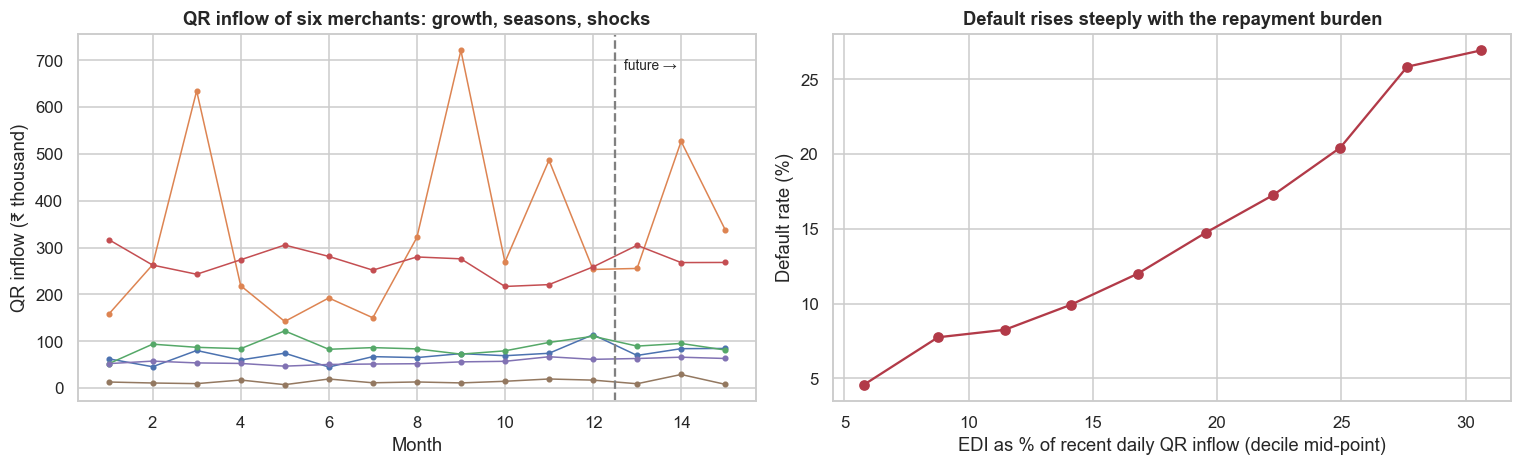

In [6]:
L = ln.merge(F[["avg3", "cv", "test"]], left_on="merchant_id", right_index=True)
L["burden_exante"] = L.edi_inr / (L.avg3 / 30)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
sample = W.sample(6, random_state=SEED)
for mid, r in sample.iterrows(): axes[0].plot(r.index, r.values / 1000, marker=".", lw=1)
axes[0].axvline(12.5, color="grey", ls="--"); axes[0].text(12.7, axes[0].get_ylim()[1] * 0.9, "future →", fontsize=9)
axes[0].set_xlabel("Month"); axes[0].set_ylabel("QR inflow (₹ thousand)"); axes[0].set_title("QR inflow of six merchants: growth, seasons, shocks")
b = pd.qcut(L.burden_exante, 10); g = L.groupby(b).default_30d_missed.mean() * 100
axes[1].plot([iv.mid * 100 for iv in g.index], g.values, "o-", color="#b23a48"); axes[1].set_xlabel("EDI as % of recent daily QR inflow (decile mid-point)")
axes[1].set_ylabel("Default rate (%)"); axes[1].set_title("Default rises steeply with the repayment burden")
plt.tight_layout(); plt.show()

**Takeaway:** **left:** six merchants show what the forecast must cope with: steady growers, seasonal swings (apparel peaks around festivals) and occasional collapses after month 12, which no history predicts. **Right:** on the 12,000 legacy loans, the default rate rises with the **repayment burden** (EDI as a share of recent daily QR inflow) from a few percent at low burdens to above 30% when the instalment takes over a quarter of daily takings. This one chart is the case for burden-based limits.

## 7. Statistical Analysis (core section)

### 7.1 Forecasting next quarter's QR inflow: naive vs model, with honest uncertainty

**(a) Why?** The loan is repaid from **future** inflow, so the limit should rest on a forecast, not on the past average. We compare:
- **Naive:** average of the last 3 months.
- **Naive + trend:** last-3 average × (1 + monthly slope)².
- **Gradient boosting** on log scale with cash-flow features.
- A **P20 quantile** gradient-boosting forecast: a conservative figure that should be beaten by the actual 80% of the time.

Out-of-sample on the test half of merchants:
- **Error:** median absolute % error and mean absolute log error.
- **Diebold–Mariano test** on the paired loss differences: are the errors really different?
- **Coverage:** a binomial test of whether the P20 forecast is exceeded 80% of the time.

In [7]:
FEATS = ["avg3", "avg6", "avg12", "slope", "cv", "last_vs_avg12", "same_month_last_year_ratio", "txn_per_month", "ticket", "payer_ratio", "active_days", "active_days_drop",
         "months_on_platform", "has_soundbox", "city_tier", "cat_c"]
tr, te = F[~F.test], F[F.test]; ytr = np.log(tr.future_avg); yte = np.log(te.future_avg)
Xtr = tr[FEATS].copy(); Xte = te[FEATS].copy()
for X_ in (Xtr, Xte):
    for c in ["avg3", "avg6", "avg12", "txn_per_month", "ticket"]: X_[c] = np.log(X_[c])
gb = HGBR(max_iter=300, learning_rate=0.06, random_state=SEED).fit(Xtr, ytr)
q20 = HGBR(loss="quantile", quantile=0.2, max_iter=300, learning_rate=0.06, random_state=SEED).fit(Xtr, ytr)
FC = {"naive: last-3-month average": np.log(te.avg3), "naive + trend": np.log(te.avg3) + 2 * te.slope, "gradient boosting (median-type)": gb.predict(Xte)}
p20 = q20.predict(Xte)
rows = []
for nm_, f in FC.items():
    e = yte - f; rows.append((nm_, np.median(np.abs(np.exp(f) / te.future_avg - 1)) * 100, np.abs(e).mean(), e.mean()))
fe = pd.DataFrame(rows, columns=["forecast", "median abs % error", "mean abs log error", "bias (log)"]).set_index("forecast")
def dm(e1, e2):
    d = np.abs(e1) - np.abs(e2); return d.mean() / (d.std(ddof=1) / np.sqrt(len(d)))
z = dm(yte - FC["naive: last-3-month average"], yte - FC["gradient boosting (median-type)"])
cover = (te.future_avg.values >= np.exp(p20)).mean(); bt = stats.binomtest(int((te.future_avg.values >= np.exp(p20)).sum()), len(te), 0.8)
def pinball(y, q, tau=0.2): u = y - q; return np.mean(np.maximum(tau * u, (tau - 1) * u))
print(f"Diebold–Mariano (naive vs boosting, absolute log error): z = {z:.1f}, p = {2 * stats.norm.sf(abs(z)):.2g}")
print(f"P20 forecast: actual ≥ P20 for {cover:.1%} of merchants (target 80%; binomial p = {bt.pvalue:.2g}); pinball loss P20 model {pinball(yte.values, p20):.4f} vs "
      f"naive×0.8 {pinball(yte.values, np.log(te.avg3.values * 0.8)):.4f}")
shock = te._shock.values == 1
print(f"Merchants hit by a future shock (6%): naive overestimates their inflow by {np.median(np.exp(FC['naive: last-3-month average'][shock]) / te.future_avg[shock] - 1):.0%} (median); "
      f"P20 by {np.median(np.exp(p20[shock]) / te.future_avg[shock] - 1):.0%}")
fe.round(4)

Diebold–Mariano (naive vs boosting, absolute log error): z = 25.8, p = 2.1e-146
P20 forecast: actual ≥ P20 for 78.5% of merchants (target 80%; binomial p = 2.3e-07); pinball loss P20 model 0.0684 vs naive×0.8 0.0821
Merchants hit by a future shock (6%): naive overestimates their inflow by 88% (median); P20 by 77%


,median abs % error,mean abs log error,bias (log)
forecast,,,
naive: last-3-month average,10.8315,0.1745,0.0165
naive + trend,9.6021,0.1734,0.0035
gradient boosting (median-type),9.3457,0.1598,0.0000


**(c)/(f) Observation:** - **The model beats the naive forecast:** median absolute error **9.3% vs 10.8%**, mean absolute log error 0.160 vs 0.175, and the **Diebold–Mariano test** confirms the difference (z = 25.8, p ≈ 1e-146). Adding a simple trend to the naive forecast closes part of the gap (9.6%).
- **The P20 forecast** is beaten by actual inflow for **78.5%** of merchants. That is slightly below the intended 80% and significant at this sample size (p ≈ 2e-7), but close. Its pinball loss (0.068) beats a naive "80% of the recent average" (0.082). It is a calibrated conservative number.
- **Shocks are unforecastable:** for the 6% of merchants whose business collapses after month 12, the naive forecast overestimates future inflow by **88%** and even P20 by **77%**.
- **(f) Business meaning:** forecasting improves sizing at the margin, but **post-disbursal daily monitoring** (pausing or restructuring the EDI when settlements drop) is what protects against shocks.

### 7.2 How does default depend on the repayment burden?

**(a) Why?** The limit decision is really a burden decision: EDI ÷ daily inflow. On the 12,000 legacy loans (whose sizes varied 0.25–1.7× monthly inflow), we measure default by **ex-ante burden** (EDI ÷ recent daily inflow, what we know at decision time) with Wilson CIs and a **Cochran–Armitage trend test**. A logistic regression adds volatility, because the same burden is riskier for a volatile business.

In [8]:
L["burden_band"] = pd.cut(L.burden_exante, [0, 0.06, 0.08, 0.10, 0.12, 0.15, 0.20, 0.25, 0.30, 5], right=False)
bb = L.groupby("burden_band").default_30d_missed.agg(["sum", "size"]); bb["default rate"] = bb["sum"] / bb["size"]
ci = [proportion_confint(r["sum"], r["size"], method="wilson") for _, r in bb.iterrows()]; bb["CI low"], bb["CI high"] = [c[0] for c in ci], [c[1] for c in ci]
x = np.arange(len(bb)); n_ = bb["size"].values; s_ = bb["sum"].values; pbar = s_.sum() / n_.sum(); xbar = (x * n_).sum() / n_.sum()
zt = (x * (s_ - n_ * pbar)).sum() / np.sqrt(pbar * (1 - pbar) * (n_ * (x - xbar) ** 2).sum())
lg = smf.logit("default_30d_missed ~ burden_exante + I(np.maximum(burden_exante - 0.10, 0)) + cv", data=L).fit(disp=0)
print(f"Cochran–Armitage trend: z = {zt:.1f}, p = {2 * stats.norm.sf(abs(zt)):.2g}")
print(f"Logistic (hinge at 10% burden): slope below 10% = {lg.params['burden_exante']:.2f}, extra slope above 10% = {lg.params['I(np.maximum(burden_exante - 0.10, 0))']:.2f} "
      f"(p = {lg.pvalues['I(np.maximum(burden_exante - 0.10, 0))']:.2g}); volatility OR per +0.1 = {np.exp(0.1 * lg.params['cv']):.2f} (p = {lg.pvalues['cv']:.2g})")
bb.round(4)

Cochran–Armitage trend: z = 21.3, p = 9.4e-101
Logistic (hinge at 10% burden): slope below 10% = 13.14, extra slope above 10% = -5.36 (p = 0.16); volatility OR per +0.1 = 1.17 (p = 6.6e-43)


,sum,size,default rate,CI low,CI high
burden_band,,,,,
"[0.0, 0.06)",21,581,0.0361,0.0238,0.0546
"[0.06, 0.08)",52,877,0.0593,0.0455,0.0769
"[0.08, 0.1)",69,880,0.0784,0.0624,0.0981
"[0.1, 0.12)",72,904,0.0796,0.0637,0.0991
"[0.12, 0.15)",138,1405,0.0982,0.0837,0.1149
"[0.15, 0.2)",284,2164,0.1312,0.1177,0.1461
"[0.2, 0.25)",366,2201,0.1663,0.1513,0.1824
"[0.25, 0.3)",540,2242,0.2409,0.2236,0.2590
"[0.3, 5.0)",230,746,0.3083,0.2762,0.3424


**(c)/(f) Observation:** - **Default rises steadily with the ex-ante burden:** 3.6% (burden < 6%), 5.9% (6–8%), 7.8–8.0% (8–12%), 9.8% (12–15%), 13.1% (15–20%), 16.6% (20–25%), 24.1% (25–30%), **30.8% (> 30%)**. The **Cochran–Armitage trend** is overwhelming (z = 21.3, p ≈ 1e-100).
- **There is no sharp "cliff" at 10% in the data:** the hinge term is not significant (p = 0.16), so the risk climbs smoothly. A 10% cap is therefore a *business* choice on a smooth curve, not a natural threshold.
- **Volatility matters on top of burden:** each +0.1 in month-to-month volatility multiplies default odds by **1.17** (p ≈ 1e-43), so the same instalment is riskier for a restaurant than for a pharmacy.
- **(f) Business meaning:** limits should be set so the instalment is a modest share of *forecast* daily inflow, with tighter caps for volatile businesses.

### 7.3 A default model for merchant loans

Burden is not the only driver. We train a gradient-boosting default model on the **model-building half** of loans (cash-flow features + ex-ante burden) and test it on loans of test-half merchants, comparing it with **burden alone** (DeLong).

In [9]:
def delong(y, preds):
    y = np.asarray(y); pos, neg = preds[:, y == 1], preds[:, y == 0]; m, n = pos.shape[1], neg.shape[1]
    tx = np.array([rankdata(p) for p in pos]); ty = np.array([rankdata(q) for q in neg]); tz = np.array([rankdata(np.r_[p, q]) for p, q in zip(pos, neg)])
    aucs = tz[:, :m].sum(1) / m / n - (m + 1) / 2 / n; v01 = (tz[:, :m] - tx) / n; v10 = 1 - (tz[:, m:] - ty) / m
    return aucs, np.atleast_2d(np.cov(v01)) / m + np.atleast_2d(np.cov(v10)) / n
LF = L.merge(F[FEATS], left_on="merchant_id", right_index=True, suffixes=("", "_f"))
DF = FEATS + ["burden_exante"]
dm_ = HGB(max_iter=300, learning_rate=0.06, random_state=SEED).fit(LF.loc[~LF.test, DF], LF.default_30d_missed[~LF.test])
pt = dm_.predict_proba(LF.loc[LF.test, DF])[:, 1]; yt = LF.default_30d_missed[LF.test].values
a_, c_ = delong(yt, np.vstack([LF.burden_exante[LF.test].values, pt])); se = np.sqrt(c_[0, 0] + c_[1, 1] - 2 * c_[0, 1])
print(f"Test loans: {len(yt):,} ({yt.sum()} defaults) | AUC burden alone {a_[0]:.4f} vs model {a_[1]:.4f}: Δ = {a_[1] - a_[0]:+.4f}, DeLong p = {2 * stats.norm.sf(abs(a_[1] - a_[0]) / se):.2g}")
imp = pd.Series({f: max(roc_auc_score(yt, LF.loc[LF.test, f]), 1 - roc_auc_score(yt, LF.loc[LF.test, f])) for f in DF}).sort_values(ascending=False)
imp.head(8).round(3).to_frame("single-feature AUC (direction-free)")

Test loans: 6,040 (867 defaults) | AUC burden alone 0.6725 vs model 0.7128: Δ = +0.0404, DeLong p = 9.4e-05


,single-feature AUC (direction-free)
burden_exante,0.6720
active_days,0.6710
payer_ratio,0.5730
cv,0.5670
avg6,0.5590
txn_per_month,0.5580
avg3,0.5580
avg12,0.5580


**Observation:** on 6,040 test loans (867 defaults), the gradient-boosting default model reaches **AUC 0.713 vs 0.673 for burden alone** (+0.040, DeLong p ≈ 1e-4). After burden, the strongest single signals are **active days per month** (0.67, a falling count is an early sign of trouble) and the **unique-payer ratio** (0.57, a diverse customer base is healthier and harder to fake). Raw turnover itself is weak (≈ 0.56): **how much a merchant sells matters less than how much of it the loan takes and how steady it is**. The model is used for risk tiers in 7.4.

### 7.4 Which limit rule? Comparing policies on a digital twin

**Why a digital twin?** Real loans show the outcome only at the size actually lent. To compare limit rules fairly, we apply each rule to **every test-half merchant** and compute the **true** expected default from the generator's hidden function, using the merchant's actual future inflow. This is possible only in simulation and is flagged as such. In real life the same comparison needs a randomised limit test (Case 15).

**Profit per offered merchant** = (1 − PD) × 12% fee × amount − PD × 60% LGD × amount. Policies:
1. **Legacy:** 1.0 × average monthly QR (the middle of the legacy range).
2. **Burden cap on the naive forecast:** EDI ≤ 10% of last-3-month daily inflow.
3. **Burden cap on the P20 forecast:** EDI ≤ 10% of the *conservative* forecast daily inflow.
4. **P20 + risk tiers:** as 3, with the cap set by the default model's risk tier (12% / 10% / 7% / no offer).

In [10]:
T = te.copy(); T["p20"] = np.exp(p20)
def amount_from_edi_share(daily_inflow, share): return np.round(share * daily_inflow * 180 / 1.12, -3)
T["burden_exante_proxy"] = 0.10
Xd = T[FEATS].copy(); Xd["burden_exante"] = 0.10; risk = dm_.predict_proba(Xd[DF])[:, 1]
tier_cap = np.select([risk < np.quantile(risk, 0.4), risk < np.quantile(risk, 0.75), risk < np.quantile(risk, 0.95)], [0.12, 0.10, 0.07], 0.0)
POL = {"1 legacy: 1.0 × avg monthly QR": np.round(T.avg3.values * 1.0, -3), "2 EDI ≤ 10% of naive daily inflow": amount_from_edi_share(T.avg3.values / 30, 0.10),
       "3 EDI ≤ 10% of P20 forecast": amount_from_edi_share(T.p20.values / 30, 0.10), "4 P20 + risk-tiered cap (12/10/7% / no offer)": amount_from_edi_share(T.p20.values / 30, tier_cap)}
fut_daily = T.future_avg.values / 30; rows, PR = [], {}
for nm_, amt in POL.items():
    off = amt > 0; edi = amt * 1.12 / 180; pdf = np.where(off, gen.true_default_prob(edi / fut_daily, T._q.values, T._vol.values), 0)
    prof_ = np.where(off, (1 - pdf) * 0.12 * amt - pdf * 0.60 * amt, 0); PR[nm_] = prof_
    rows.append((nm_, off.mean(), amt[off].mean(), (pdf * amt).sum() / amt.sum(), pdf[off].mean(), prof_.mean(), amt.sum() / 1e7))
pol = pd.DataFrame(rows, columns=["policy", "share offered", "avg loan ₹", "₹-weighted default", "default rate (offered)", "profit per merchant ₹", "₹ crore lent (test half)"]).set_index("policy")
base_ = "1 legacy: 1.0 × avg monthly QR"
for k in PR:
    d = PR[k] - PR[base_]; bs = [d[RNG.integers(0, len(d), len(d))].mean() for _ in range(1000)]
    pol.loc[k, "Δ profit vs legacy"] = d.mean(); pol.loc[k, "CI low"] = np.percentile(bs, 2.5); pol.loc[k, "CI high"] = np.percentile(bs, 97.5)
pol.round(4)

,share offered,avg loan ₹,₹-weighted default,default rate (offered),profit per merchant ₹,₹ crore lent (test half),Δ profit vs legacy,CI low,CI high
policy,,,,,,,,,
1 legacy: 1.0 × avg monthly QR,1.0000,"151,120.0419",0.1239,0.1370,"4,651.6249",302.8899,0.0000,0.0000,0.0000
2 EDI ≤ 10% of naive daily inflow,1.0000,"80,955.4458",0.0629,0.0707,"6,046.8434",162.2590,"1,395.2184","1,174.8521","1,634.5459"
3 EDI ≤ 10% of P20 forecast,1.0000,"73,003.4426",0.0558,0.0660,"5,829.5577",146.3208,"1,177.9327",899.4171,"1,456.2605"
4 P20 + risk-tiered cap (12/10/7% / no offer),0.9500,"78,071.7962",0.0497,0.0598,"6,244.5379",148.6487,"1,592.9130","1,324.4677","1,885.9168"


**(c)/(f) Observation:** on all 20,043 test-half merchants (digital twin):
- **Legacy (1 × monthly QR):** average loan ₹1.51 lakh, **13.7% default**, ₹4,652 profit per merchant.
- **EDI ≤ 10% of naive inflow:** half the loan size (₹81k), 7.1% default, **₹6,047** (+₹1,395, CI ₹1,175–1,635).
- **EDI ≤ 10% of P20 forecast:** ₹73k, 6.6% default, ₹5,830. It is *safer* but **less profitable** than the naive cap, because it is too conservative for most merchants.
- **P20 + risk tiers** (12% / 10% / 7% / no offer for the riskiest 5%): ₹78k, **6.0% default** (guardrail ✅), **₹6,245 per merchant (+₹1,593, CI ₹1,324–1,886 vs legacy)**, the best.

**(f) Business meaning:** the legacy rule over-lends. Most of the gain comes from capping the burden at all; risk tiering adds the rest by lending more to safe merchants and nothing to the riskiest 5%. Real-world validation needs a randomised limit test, because this comparison uses the simulation's true default function.

### 7.5 KYC name matching: which matcher, and where to set the thresholds?

**(a) Why?** Before disbursal, the KYC name must match the bank-account name returned by the penny-drop check. We compare four matchers (FuzzyWuzzy is not in our library list, so its token-sort and token-set ratios are re-implemented with Python's `difflib`):
1. **Exact after normalisation:** lower-case, remove honorifics and punctuation, collapse spaces.
2. **Token-sort ratio:** sort the words, then compare strings (robust to word order).
3. **Token-set ratio:** compares shared words (robust to dropped middle names and extra words).
4. **Hybrid:** token-set + Jaro–Winkler per token + initials expansion ("R Sharma" matches "Ramesh Sharma"), taking the best word alignment.

Evaluated on the 30,000 labelled pairs: AUC, recall by variant type, and **McNemar** for paired error comparison. The decision policy has **two zones**:
- **Auto-accept** at or above a threshold set so that false accepts are ≤ 0.5% of different-person pairs.
- **Manual review** for everything else, including blank names.

We do not auto-*reject*: a name mismatch is a reason to check, not to refuse a merchant who may simply be "Mohd" on one document and "Mohammed" on another.

In [11]:
HON = r"\b(mr|mrs|ms|smt|shri|sri|dr|m/s)\b\.?"
def norm(s): s = re.sub(HON, " ", str(s).lower()); s = re.sub(r"[^a-z ]", " ", s); return " ".join(s.split())
def ratio(a, b): return difflib.SequenceMatcher(None, a, b).ratio() * 100
def token_sort(a, b): return ratio(" ".join(sorted(a.split())), " ".join(sorted(b.split())))
def token_set(a, b):
    A, B = set(a.split()), set(b.split()); inter = " ".join(sorted(A & B)); da = " ".join(sorted(A - B)); db = " ".join(sorted(B - A))
    s1, s2 = (inter + " " + da).strip(), (inter + " " + db).strip()
    return max(ratio(inter, s1) if inter else 0, ratio(inter, s2) if inter else 0, ratio(s1, s2))
def jaro_winkler(s, t):
    if s == t: return 1.0
    ls, lt = len(s), len(t)
    if not ls or not lt: return 0.0
    md = max(ls, lt) // 2 - 1; sm = [False] * ls; tm = [False] * lt; m = 0
    for i in range(ls):
        for j in range(max(0, i - md), min(i + md + 1, lt)):
            if not tm[j] and s[i] == t[j]: sm[i] = tm[j] = True; m += 1; break
    if not m: return 0.0
    k = tr_ = 0
    for i in range(ls):
        if sm[i]:
            while not tm[k]: k += 1
            if s[i] != t[k]: tr_ += 1
            k += 1
    j = (m / ls + m / lt + (m - tr_ / 2) / m) / 3; p = 0
    for a_, b_ in zip(s[:4], t[:4]):
        if a_ == b_: p += 1
        else: break
    return j + 0.1 * p * (1 - j)
def hybrid(a, b):
    A, B = a.split(), b.split()
    if not A or not B: return 0.0
    if len(A) > len(B): A, B = B, A
    def tok(x, y): return 1.0 if (len(x) == 1 and y.startswith(x)) or (len(y) == 1 and x.startswith(y)) else jaro_winkler(x, y)
    used, sc = set(), []
    for x in A:
        best = max(((tok(x, y), j) for j, y in enumerate(B) if j not in used), default=(0, -1)); sc.append(best[0]); used.add(best[1])
    return 100 * np.mean(sc) * (0.85 + 0.15 * len(A) / len(B))
names = nm.copy(); names["a"] = names.kyc_name.map(norm); names["b"] = names.bank_account_name.map(norm); blank = names.b == ""
for nm_, f in (("exact (normalised)", lambda a, b: 100.0 * (a == b)), ("token-sort ratio", token_sort), ("token-set ratio", token_set), ("hybrid (set + Jaro–Winkler + initials)", hybrid)):
    names[nm_] = [0.0 if b == "" else f(a, b) for a, b in zip(names.a, names.b)]
MATCHERS = ["exact (normalised)", "token-sort ratio", "token-set ratio", "hybrid (set + Jaro–Winkler + initials)"]
y = names._is_same_person.values; nb = ~blank.values
def accept_threshold(score, y, fa_max=0.005):
    neg = score[y == 0]; ok = [t for t in np.unique(score) if (neg >= t).mean() <= fa_max]     # smallest threshold with ≤ 0.5% impostors at/above it
    return min(ok) if ok else np.inf
mrows, ACC = [], {}
for m_ in MATCHERS:
    s = names[m_].values[nb]; yy = y[nb]; hi = accept_threshold(s, yy); acc = s >= hi; ACC[m_] = acc
    fa = (acc & (yy == 0)).sum(); fa_hi = proportion_confint(fa, (yy == 0).sum(), method="wilson")[1]
    mrows.append((m_, roc_auc_score(yy, s), hi, fa / (yy == 0).sum(), fa_hi, acc[yy == 1].mean(), (~acc).mean(), int(((s >= 99.999) & (yy == 0)).sum())))
mt = pd.DataFrame(mrows, columns=["matcher", "AUC", "accept at/above", "false-accept rate", "FA CI high", "genuine auto-accepted", "share sent to review", "impostors scoring 100"]).set_index("matcher")
a1, a2 = ACC["exact (normalised)"] == (y[nb] == 1), ACC["hybrid (set + Jaro–Winkler + initials)"] == (y[nb] == 1)
mc = mcnemar([[int((a1 & a2).sum()), int((a1 & ~a2).sum())], [int((~a1 & a2).sum()), int((~a1 & ~a2).sum())]], exact=False, correction=True)
print(f"Blank bank names routed to manual review: {blank.sum()} | McNemar (auto-accept correctness, exact vs hybrid): χ² = {mc.statistic:.0f}, p = {mc.pvalue:.2g}")
mt.round(4)

Blank bank names routed to manual review: 150 | McNemar (auto-accept correctness, exact vs hybrid): χ² = 7406, p = 0


,AUC,accept at/above,false-accept rate,FA CI high,genuine auto-accepted,share sent to review,impostors scoring 100
matcher,,,,,,,
exact (normalised),0.7677,100.0000,0.0002,0.0013,0.5355,0.5435,1
token-sort ratio,0.9733,82.0513,0.0048,0.0073,0.7815,0.3331,1
token-set ratio,0.9715,inf,0.0000,0.0009,0.0000,1.0000,35
hybrid (set + Jaro–Winkler + initials),0.9837,95.0185,0.0005,0.0017,0.8268,0.2951,1


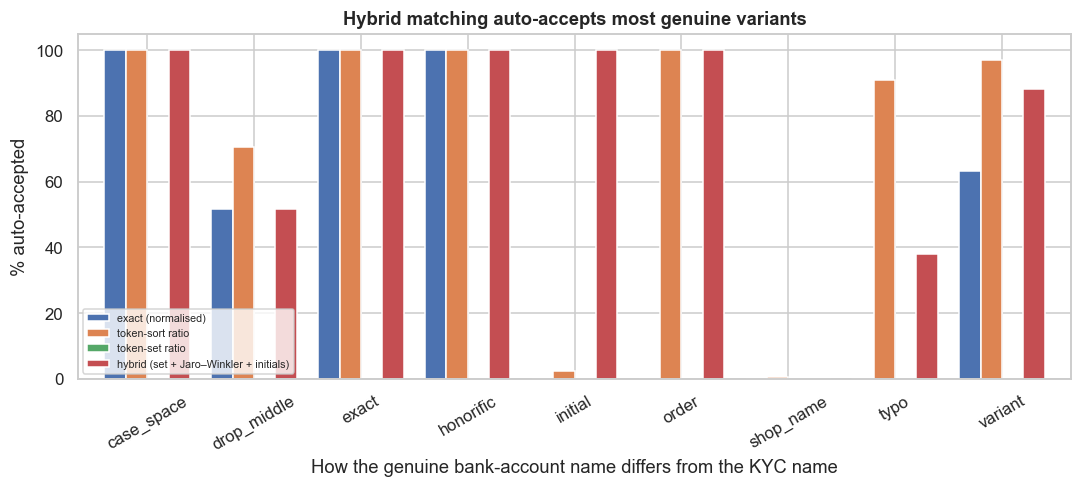

,same person?,exact (normalised),token-sort ratio,token-set ratio,hybrid (set + Jaro–Winkler + initials)
_variant,,,,,
case_space,yes,1.0000,1.0000,0.0000,1.0000
drop_middle,yes,0.5180,0.7070,0.0000,0.5180
exact,yes,1.0000,1.0000,0.0000,1.0000
honorific,yes,1.0000,1.0000,0.0000,1.0000
initial,yes,0.0000,0.0250,0.0000,1.0000
order,yes,0.0000,1.0000,0.0000,1.0000
same_first,no,0.0020,0.0090,0.0000,0.0020
same_surname,no,0.0000,0.0120,0.0000,0.0010
shop_name,yes,0.0000,0.0050,0.0000,0.0000


In [12]:
var = names[nb].groupby("_variant").apply(lambda g: pd.Series({m_: (g[m_] >= mt.loc[m_, "accept at/above"]).mean() for m_ in MATCHERS}))
var.insert(0, "same person?", names[nb].groupby("_variant")._is_same_person.first().map({1: "yes", 0: "no"}))
fig, ax = plt.subplots(figsize=(10, 4.6))
v_ = var[var["same person?"] == "yes"].drop(columns="same person?") * 100
v_.plot(kind="bar", ax=ax, width=0.8); ax.set_xlabel("How the genuine bank-account name differs from the KYC name"); ax.set_ylabel("% auto-accepted")
ax.set_title("Hybrid matching auto-accepts most genuine variants"); ax.tick_params(axis="x", rotation=30); ax.legend(fontsize=7, loc="lower left")
plt.tight_layout(); plt.show()
var.round(3)

**Takeaway:** - **Exact matching after normalisation** (lower case, honorifics and punctuation removed) auto-accepts only **53.6%** of genuine pairs: it fails on every initial, word-order swap and spelling variant. AUC 0.77.
- **Token-sort ratio** handles word order and most typos (AUC 0.973; 78% auto-accepted at a 0.48% false-accept rate), but not initials.
- **Token-set ratio** (FuzzyWuzzy's popular choice) has a high AUC (0.972) but **cannot be used to auto-accept**: it gives a perfect 100 to **35 impostor pairs** where one name's words are a subset of the other's ("Ramesh Kumar Sharma" vs "Ramesh Sharma"). No threshold meets the 0.5% false-accept limit.
- **The hybrid matcher** has the best AUC (**0.984**). It auto-accepts **82.7%** of genuine pairs at a **0.05%** false-accept rate (Wilson upper bound 0.17%), and handles initials (100%), order (100%), honorifics, spacing and most spelling variants (88%). It is weaker on typos (38%) than token-sort (91%).
- **Paired comparison:** exact vs hybrid auto-accept correctness differs overwhelmingly (McNemar χ² = 7,406).
- **Shop names in place of owner names** are never auto-accepted by any matcher. That is the right outcome, as they need human review.
- **Chart:** auto-accept rate by variant type for each matcher.

**Business meaning:** matcher choice changes how many merchants get "five-second" loans by **~30 points**. A combined score (hybrid + token-sort, or a small learned model) would add the typo coverage.

### 7.6 How much can be decided in "five seconds"?

The documented turnaround fell from two days to five seconds. Only applications that need **no human step** can be that fast. We combine the two automatic gates for test-half merchants: (i) a limit offered by policy 4, and (ii) a name pair in the hybrid matcher's auto-accept zone (name pairs assigned to merchants at random, for illustration).

In [13]:
s_h = names["hybrid (set + Jaro–Winkler + initials)"].values; hi = mt.loc["hybrid (set + Jaro–Winkler + initials)", "accept at/above"]
zone = np.where(blank.values, "review", np.where(s_h >= hi, "auto-accept", "review"))
zone_m = RNG.choice(zone, len(T)); offered = POL["4 P20 + risk-tiered cap (12/10/7% / no offer)"] > 0
auto = offered & (zone_m == "auto-accept"); lo_, hi_ = proportion_confint(auto.sum(), len(auto), method="wilson")
print(f"Fully automatic decisions: {auto.mean():.1%} of test merchants (CI {lo_:.1%}–{hi_:.1%}); offered but name needs review: {(offered & (zone_m == 'review')).mean():.1%}; "
      f"no offer (risk tier): {(~offered).mean():.1%}")
print(f"Exact matching alone would auto-accept only {mt.loc['exact (normalised)', 'genuine auto-accepted']:.1%} of genuine names vs {mt.loc['hybrid (set + Jaro–Winkler + initials)', 'genuine auto-accepted']:.1%} for hybrid")

Fully automatic decisions: 66.8% of test merchants (CI 66.2%–67.5%); offered but name needs review: 28.1%; no offer (risk tier): 5.0%
Exact matching alone would auto-accept only 53.6% of genuine names vs 82.7% for hybrid


**Observation:** combining both automatic gates, **66.8%** of test merchants (CI 66.2–67.5%) can be decided with **no human step**: offered a limit *and* their name auto-accepted. A further 28.1% are offered a limit but need a quick name review, and 5.0% get no offer (riskiest tier). With exact matching, only about 54% of genuine names would pass automatically. **Business meaning:** "two days to five seconds" is realistic for about two-thirds of merchants. The rest need minutes of review rather than days, as long as review queues are staffed for ~30% of applications.

## 8. ML Section — brief

- **Forecast:** gradient boosting on log inflow, with a **quantile (P20)** variant. A quantile forecast answers the credit question ("how low could inflow plausibly go?") better than a mean forecast. No tuning (per the brief).
- **Default model:** gradient boosting on cash-flow features + ex-ante burden. Used for risk tiers, not as the only gate.
- **Name matching:** deterministic similarity functions, which are auditable. An ML matcher trained on the labelled pairs could add a little, but an explainable score with three zones is easier to defend to auditors and the RBI.

## 9. Business Translation — ₹ impact

In [14]:
SCALE = 1e5 / len(T)                                                            # scale: 1 lakh merchants offered per quarter (assumption, D-16-07)
money = pol[["share offered", "₹-weighted default", "profit per merchant ₹", "Δ profit vs legacy", "CI low", "CI high"]].copy()
money["₹ crore profit per 1 lakh merchants"] = pol["profit per merchant ₹"] * 1e5 / 1e7; money["vs legacy ₹ crore"] = pol["Δ profit vs legacy"] * 1e5 / 1e7
avg_loan = pol.loc["4 P20 + risk-tiered cap (12/10/7% / no offer)", "avg loan ₹"]
REVIEW_COST, ABANDON, WRONG_PAYEE_LOSS = 40, 0.05, 0.6 * avg_loan               # ₹40 per review; 5% of reviewed genuine merchants drop out (delay); wrong payee loses 60%
nm_cost = []
for m_ in MATCHERS:
    r = mt.loc[m_]; n_pairs = 1e5; gen_rev = 0.85 * (1 - r["genuine auto-accepted"])
    cost = n_pairs * r["share sent to review"] * REVIEW_COST + n_pairs * gen_rev * ABANDON * 0.12 * avg_loan + n_pairs * 0.15 * r["false-accept rate"] * WRONG_PAYEE_LOSS
    nm_cost.append((m_, r["share sent to review"], cost / 1e5))
print(f"Name-matching cost per 1 lakh disbursals (review ₹{REVIEW_COST}; {ABANDON:.0%} of reviewed genuine merchants abandon, losing a 12% fee on ₹{avg_loan:,.0f}; wrong-payee loss ₹{WRONG_PAYEE_LOSS:,.0f}):")
print(pd.DataFrame(nm_cost, columns=["matcher", "share reviewed", "₹ lakh"]).set_index("matcher").round(3).to_string())
money.round(3)

Name-matching cost per 1 lakh disbursals (review ₹40; 5% of reviewed genuine merchants abandon, losing a 12% fee on ₹78,072; wrong-payee loss ₹46,843):
                                        share reviewed   ₹ lakh
matcher                                                        
exact (normalised)                              0.5430 208.2620
token-sort ratio                                0.3330 133.8090
token-set ratio                                 1.0000 438.1660
hybrid (set + Jaro–Winkler + initials)          0.2950  83.9570


,share offered,₹-weighted default,profit per merchant ₹,Δ profit vs legacy,CI low,CI high,₹ crore profit per 1 lakh merchants,vs legacy ₹ crore
policy,,,,,,,,
1 legacy: 1.0 × avg monthly QR,1.0000,0.1240,"4,651.6250",0.0000,0.0000,0.0000,46.5160,0.0000
2 EDI ≤ 10% of naive daily inflow,1.0000,0.0630,"6,046.8430","1,395.2180","1,174.8520","1,634.5460",60.4680,13.9520
3 EDI ≤ 10% of P20 forecast,1.0000,0.0560,"5,829.5580","1,177.9330",899.4170,"1,456.2600",58.2960,11.7790
4 P20 + risk-tiered cap (12/10/7% / no offer),0.9500,0.0500,"6,244.5380","1,592.9130","1,324.4680","1,885.9170",62.4450,15.9290


**Takeaway (business reading):** - **Limits (per 1 lakh merchants offered, one 6-month cycle):** the legacy rule earns ≈ ₹46.5 crore; the burden cap on naive inflow ≈ ₹60.5 crore; **P20 + risk tiers ≈ ₹62.4 crore (+₹15.9 crore vs legacy)** while lending about half as much capital. That frees balance sheet for more merchants.
- **Name matching (per 1 lakh disbursals),** counting ₹40 per review, 5% of reviewed genuine merchants dropping out because of the delay, and 60% loss on a wrong-payee disbursal:

| Matcher | Cost (₹ lakh per lakh disbursals) | Share reviewed |
|---|---|---|
| Hybrid | ≈ **84** | 29.5% |
| Token-sort | ≈ 134 | — |
| Exact | ≈ 208 | 54% |
| Token-set | ≈ 438 | 100% |

- **Reading:** the larger ₹ lever is **burden-based sizing**; the matcher's value is mostly speed and conversion. All figures rest on the stated fee, LGD and drop-out assumptions.

## 10. Recommendation and Decision

**Decision against the hypotheses:**
- **H1 ✅:** the model forecast beats naive (DM p ≈ 1e-146). The P20 coverage is 78.5%, slightly below 80% but usable.
- **H2 ✅:** default rises with burden (no sharp kink).
- **H3 ✅:** burden-based, risk-tiered limits beat legacy by +₹1,593 per merchant, with default 6.0% (guardrail ≤ 8% ✅).
- **H4 ✅:** the hybrid matcher beats exact (McNemar). False accepts 0.05% (target ≤ 0.5% ✅).

**I recommend:**
1. **Limit = what keeps the instalment ≤ 10–12% of forecast daily QR inflow**, risk-tiered by the default model (no offer for the riskiest ~5%), with tighter caps for volatile categories.
2. **Daily monitoring after disbursal:** if 7-day settlements fall by more than 40%, pause or stretch the EDI automatically, because no forecast sees shocks coming.
3. **Name check:** use the hybrid matcher for auto-accept (threshold ≈ 95), send everything else to a review queue sized for ~30% of applications, never auto-reject on name alone, and do not use token-set ratio for acceptance.
4. **Validate live:** run a randomised limit test (e.g., 8% / 10% / 12% burden caps) on new merchants to confirm the burden–default curve before full roll-out.
5. **Guard the data:** monitor payer diversity and round-tripping, so merchants cannot inflate QR inflow to raise limits.

**KPIs:** default and loss rate by burden band; profit per merchant offered; share of applications fully automated (target ≥ 65%); name-review queue time; false-accept incidents (wrong-payee disbursals); share of merchants restructured after a settlement drop.

## 11. Risks, Limitations and Next Steps

- **Digital twin:** the policy comparison in 7.4 uses the generator's true default function. In production, run a **randomised limit test** (Case 15) before switching rules, because the burden–default curve is the key unknown.
- **Shocks:** 6% of merchants suffered a business shock no history could predict. Keep EDI monitoring with automatic restructuring (pause or extend) when daily inflow drops, rather than relying only on the upfront limit.
- **Self-dealing and circular flows:** QR inflow can be inflated by merchants paying themselves to raise their limit. Add checks on payer diversity (the unique-payer ratio feature) and on round-tripping.
- **Name matching:** thresholds were tuned on synthetic variants. Tune on real penny-drop results, monitor false accepts via fraud reports, and keep human review for the middle zone. Never auto-reject without a clear reason shown to the merchant.
- **Regulation:** the lending partner (an NBFC or bank) owns the credit decision under RBI's Digital Lending Guidelines. The limit rule, its validation and the KFS (Key Fact Statement) must be documented.

## 12. Appendix

| Quantity | Formula |
|---|---|
| EDI | loan × (1 + fee) / 180 days |
| Repayment burden | EDI ÷ daily QR inflow |
| Diebold–Mariano | DM = d̄ / (s_d/√n), dₜ = |e₁ₜ| − |e₂ₜ| |
| Pinball loss (τ = 0.2) | mean(max(τ·u, (τ − 1)·u)), u = y − q̂ |
| Expected profit | (1 − PD)·fee·A − PD·LGD·A |
| Token-sort ratio | similarity of the word-sorted strings |
| Token-set ratio | max similarity among {shared words, shared + rest of A, shared + rest of B}; scores 100 whenever one name's words are a subset of the other's |
| Jaro–Winkler | Jaro similarity + 0.1 × common prefix (≤ 4) × (1 − Jaro) |

| Term | Meaning |
|---|---|
| QR settlement | Money from customers' QR payments credited to the merchant |
| EDI | Equated daily instalment, deducted from settlements |
| Quantile (P20) forecast | A value the outcome exceeds 80% of the time |
| Digital twin | A simulation in which every counterfactual outcome is known |
| Penny drop | A ₹1 test transfer that returns the bank-account holder's name |
| False accept | Treating two different people as the same (paying the wrong person) |